# Reexecução dos estudos com os artefatos originais — 03/10/2026

Reexecutei a **avaliação** de DR-BioL/DAT e o notebook oficial MosquitoSong+, com as arquiteturas, pesos e entradas disponibilizados pelos autores. Os resultados internos ficaram próximos dos artigos. **Não refiz os treinamentos dos artigos, suas dez repetições de treino ou todos os experimentos.** A avaliação original e os diagnósticos externos são apresentados separadamente. Não há reprodução integral de todos os estudos, nem equivalência bit a bit de ambientes sem versões publicadas.

## Comparação com os resultados publicados

| Estudo e tarefa | Publicado | Reexecução realizada | Diferença |
|---|---:|---:|---:|
| DR-BioL, 8 espécies, teste oficial | 85,345% | 85.26% | -0.082 p.p. |
| DAT, mesmas 8 espécies e teste | 79,583% | 79.39% | -0.189 p.p. |
| MosquitoSong+, espécie e sexo, Exp. 1 / Exp. 3 | 91,8% / 93,3% | 92.78%, notebook disponível | +0,978 / −0,522 p.p. |
| Fernandes, binário | 97,65%; sensibilidade 88,49% | CSV dos autores recalculado: 97,654%; 88,496% | Conferência numérica; sem novo experimento |

O DR-BioL/DAT foi comparado à Tabela 4 do [preprint v1](https://arxiv.org/html/2510.00346v1), usando o [código original](https://github.com/Yuanbo2020/DR-BioL) e o [dataset oficial](https://zenodo.org/records/17287037). AUC micro: DR-BioL 0.97312 contra 0,9732; DAT 0.96065 contra 0,9607. AP micro: 0.89956 contra 0,9002; 0.84827 contra 0,8481.

No [artigo MosquitoSong+](https://journals.plos.org/plosone/article?id=10.1371/journal.pone.0310121), 91,8% corresponde ao experimento 1 e 93,3% ao experimento 3. O [repositório disponibilizado](https://github.com/akaraspt/mosquitosongp) não identifica de forma inequívoca qual experimento corresponde ao conjunto dos dez H5. O experimento 3 também usa dados e ruídos adicionais que não constam nesse pacote. Por isso, não afirmo ter reproduzido exatamente a linha de 93,3% do artigo. A comparação mostra as duas referências, sem escolher a mais conveniente. O macro F1 combinado reproduzido foi 0.91894; a média entre folds do notebook foi 0.91909 antes do arredondamento.

![Resultados internos](reports/assets/faithful_author_accuracy.png)

## O que permaneceu fiel aos artefatos

**DR-BioL/DAT:** todos os 10.256 exemplos do teste no pickle oficial; Mel pré-calculado 200 × 64; oito classes; batch 64; pesos originais carregados com `strict=True`; saída por argmax. Preservei `MC_dropout=True`, que mantém dropout na última camada mesmo com `eval()`. Fiz cinco avaliações com sementes 0–4 do mesmo checkpoint, não cinco treinamentos. Desvio entre essas avaliações: 0.042 p.p. para DR-BioL e 0.059 p.p. para DAT. O arquivo ZIP de 1,4 GB confere com o MD5 oficial `4d3fe3742d104a022bbea013b4bd290e`.

O `Evaluation.py` foi executado com seu cálculo e gráficos originais. Para DAT, somente a escolha da variável `model_name` foi trocada para a alternativa indicada no próprio arquivo. A compatibilidade de sklearn exigiu aceitar o argumento posicional de `compute_class_weight` como argumento nomeado; a fórmula permanece a da biblioteca. O código e os pesos originais no checkout não foram alterados. O ambiente local foi PyTorch 2.12.0+rocm7.2, Python 3.14.7 e GPU AMD Radeon RX 9070 XT; o repositório não fixa todas as versões do ambiente original.

**MosquitoSong+:** executei todas as células de código originais, sem editar seu texto; dez H5; 1.324 WAVs e 12 ruídos; resampling por librosa; 300 ms com 150 ms de passo e jitter original; partições e limites originais; simulação de ganho, atraso, dois microfones e cancelamento; três ganhos e suas combinações; relatórios e CSVs oficiais. Instrumentei somente o registro dos argumentos de `classification_report`, devolvendo seu resultado original. Foram 600 epochs base por fold, seis versões simuladas de cada epoch e 36.000 previsões combinadas entre folds. Elas não representam 36.000 gravações independentes.

TensorFlow **2.4.0** foi instalado em um ambiente separado, com NumPy 1.19.5, librosa 0.8.1, h5py 2.10.0 e pandas 1.3.5. O README sugere Python 3.7; usei 3.8.20 e execução em CPU. O README não fixa as versões das demais bibliotecas. O arquivo completo de versões e os hashes estão nos resultados. Preservar código, pesos e dados permite reexecutar esta avaliação; não elimina a diferença do ambiente nem completa os artefatos ausentes.

## Resposta binária derivada dos modelos originais

Sem novo treino ou limiar ajustado: DR-BioL/DAT é Aedes quando o argmax original é a classe 2; MosquitoSong+ é Aedes quando o argmax é a classe 0 ou 1, feminino ou masculino. As métricas abaixo pertencem **aos respectivos testes nativos**, não ao Arduino nem ao Drive. As classes negativas são outras espécies de mosquito; estes números não avaliam a ausência de mosquito.

| Modelo original | Precisão Aedes | Sensibilidade Aedes | Especificidade |
|---|---:|---:|---:|
| DR_BioL_CNN | 92.70% | 96.17% | 96.25% |
| DAT_CNN | 90.80% | 89.79% | 95.49% |
| MosquitoSong+ original notebook | 92.07% | 88.51% | 96.98% |

Isso mostra que um modelo original consegue identificar muitos Aedes **no teste distribuído pelos autores**. Não demonstra a mesma sensibilidade num sensor, ambiente, enxame ou gravação diferente.

## Auditoria das partições

No notebook MosquitoSong+, executei a função original `split_data` e rastreei cada janela de volta ao WAV e ao intervalo de amostras que a originaram. Em todos os folds há gravações presentes tanto nos arrays chamados treino quanto nos de teste: **9–13 gravações por fold**, com **12–16 pares de janelas com amostras realmente sobrepostas** entre essas partições. Também há sobreposição com validação. Os dez folds completos estão em `mosquitosong/split_audit.csv`.

É evidência de dependência nas partições construídas pelo notebook público, não uma acusação de fraude nem a prova de quanto a acurácia foi inflada. Como os H5 não trazem um manifesto de quais gravações foram usadas no treino, não posso confirmar retrospectivamente se cada peso foi treinado exatamente com esses arrays. Também não há identificação completa dos mosquitos individuais. Uma validação rigorosa deve separar gravações e, quando possível, indivíduos/sessões **antes** de criar janelas.

No DR-BioL, a auditoria por hash dos vetores Mel não encontrou entradas idênticas entre treino, validação e teste. O pickle não fornece identificadores das gravações/sessões originais. Logo, **zero duplicatas exatas não prova independência entre gravações**. A avaliação executada é a mistura D1–D4 do teste oficial; não reproduzi o experimento separado de domínio nunca visto da Tabela 1.

## Comparação externa com os nossos modelos

Mantive os 32 arquivos e 641 intervalos de 0,992 s do teste anterior, sendo 493 positivos e 148 negativos pelo rótulo do arquivo. **É uma comparação retrospectiva em arquivos já avaliados**, sem novo treino, escolha por resultado ou ajuste de limiar. Não apresento este conjunto como recém-descoberto ou novo teste cego da nossa linha de pesquisa. Não há anotação temporal de presença de voo em cada intervalo, nem garantia de novos indivíduos por identificadores; são limites desta comparação.

O modelo MosquitoSong+ requer 300 ms. Declarei antes da avaliação a média dos oito escores de três sub-janelas reais de 300 ms em cada intervalo comum, e um ensemble dos dez pesos sem selecionar o melhor fold. Essa agregação é **uma extensão nossa**. Também mantive resultados separados no protocolo de janelas de 300 ms, com jitter/passo originais. Em gravações mono reais não apliquei ganho artificial nem inventei cancelamento físico entre dois microfones; este diagnóstico não reproduz o sistema de aquisição de dois microfones do estudo.

| Modelo congelado | Precisão | Sensibilidade Aedes | Especificidade | Acerto balanceado | Drive |
|---|---:|---:|---:|---:|---:|
| prior_dryad+humbug__svm_rbf | 65.38% | 3.45% | 93.92% | 48.68% | 32/107 |
| prior_dryad__logistic | 83.33% | 32.45% | 78.38% | 55.42% | 1/107 |
| prior_humbug__svm_rbf | 100.00% | 1.01% | 100.00% | 50.51% | 11/107 |
| ridge_contrast | 73.88% | 20.08% | 76.35% | 48.22% | 34/107 |
| ridge_contrast_swarm | 72.86% | 10.34% | 87.16% | 48.75% | 30/107 |
| ridge_control | 76.32% | 5.88% | 93.92% | 49.90% | 7/107 |
| svm_multipitch | 79.86% | 45.03% | 62.16% | 53.60% | 57/107 |
| trees_multipitch | 74.87% | 28.40% | 68.24% | 48.32% | 78/107 |
| MosquitoSong+ ensemble derivado (10 pesos originais) | — | 0.00% | 100.00% | 50.00% | 0/107 |

Os folds originais, individualmente, ficaram entre 0.00% e 1.01% de sensibilidade nos mesmos intervalos externos; no Drive, entre 0 e 8 acertos de 107. O ensemble derivado reconheceu **0/107** no Drive. Há 105 intervalos válidos e dois rejeitados pelo critério de qualidade comum. O Drive foi rotulado como enxame de Aedes pelo usuário e tem somente a classe positiva: permite medir a proporção reconhecida sob essa referência, **não** especificidade, precisão informativa, taxa de falsos alarmes ou confiabilidade geral. Os denominadores de 300 ms são diferentes e constam nos arquivos; não os misturei com os 107 intervalos.

![Diagnóstico externo](reports/assets/faithful_external_comparison.png)

A diferença de aquisição e pré-processamento limita o diagnóstico externo dos pesos MosquitoSong+. Ainda assim, os resultados não sustentam seu uso direto nos nossos áudios mono. Os nossos candidatos tampouco alcançaram sensibilidade de 60% nesses mesmos intervalos. **Não há evidência suficiente para liberar o modelo no cenário do usuário.**

Não testei DR-BioL no Drive sob a etiqueta de reprodução exata: o repositório entrega Mel pronto e não entrega o extrator de WAV completo que produziu esse pickle. Escolher parâmetros aproximados e chamar o resultado de original repetiria o problema das adaptações anteriores. Também não comparei diretamente a acurácia multiclasses nativa de 85% com a sensibilidade binária externa dos nossos modelos.

## Estudos que não puderam ser reproduzidos integralmente

**Fernandes:** o [artigo](https://arxiv.org/pdf/2008.09024) descreve cortes manuais de ruído/ausência de mosquito, conversão e resampling com SoX. O código usa janela de **1,248 s**, espectrograma transposto/achatado e reorganizado, duas saídas sigmoid, RMSprop e dez épocas; nossas adaptações anteriores diferem desses detalhes. O checkout público e seus releases não forneceram o pacote de pesos nem a base curada/NPZ. Recalculei o CSV original de dez folds: as médias ficam a menos de 0,01 ponto percentual das publicadas, com pequenas diferenças na última casa decimal. Isso não é novo treino nem teste. Não substituí a base curada por áudios brutos e não chamei isso de réplica exata.

**Altayeb/TinyML:** baixei o [repositório dos autores](https://github.com/Mjrovai/wingbeat-mosquito-tinyml), que contém a base, o artigo e notebooks. O notebook de treinamento depende de vetores exportados de um projeto Edge Impulse; os endpoints de X/Y retornaram HTTP 401 em acesso anônimo. Não obtive um export público versionado com os vetores/partições/pesos necessários para repetir a avaliação específica do estudo. Não gerei modelos, bibliotecas ou firmware para Arduino.

As estratégias anteriores continuam rotuladas como adaptações. A reprodução da avaliação original não deve ser confundida com refazer todos os treinos, todos os estudos ou demonstrar generalização.

## Artefatos e execução

Resultados em `results/faithful_reproduction_2026_10_03/`: tabela artigo/reexecução, métricas binárias nativas, previsões originais por fold/semente, seis CSVs oficiais, notebook original executado, auditorias, protocolos, versões e hashes. O notebook deste relatório foi executado e o HTML gerado. O áudio privado não foi incorporado aos artefatos públicos. Firmware, instaladores e modelos anteriores permanecem intactos.

Com os checkouts fixados nas revisões dos manifestos, a base oficial baixada e os WAVs/H5 nas pastas descritas pelo README original:

```bash
.venv/bin/python fetch_faithful_dr_biol.py
.venv/bin/python run_author_dr_biol.py
TF_CPP_MIN_LOG_LEVEL=2 MPLBACKEND=Agg tmp/faithful_reproduction_2026_10_03/env_tf24/bin/python run_author_mosquitosong.py
tmp/faithful_reproduction_2026_10_03/env_tf24/bin/python audit_author_mosquitosong.py
tmp/faithful_reproduction_2026_10_03/env_tf24/bin/python evaluate_author_mosquitosong_external.py
.venv/bin/python build_faithful_reproduction_artifacts.py
```

A criação do ambiente isolado e o preparo dos 641/107 intervalos estão documentados em `results/faithful_reproduction_2026_10_03/REPRODUCING.md`. Os comandos de avaliação não treinam, não escolhem limiares e não compilam Arduino.


,study,model,task,test_examples,repeated_evaluation_draws,training_rerun,published_accuracy,published_roc_auc_micro,published_average_precision_micro,accuracy,...,average_precision_micro,average_precision_micro_dropout_sd,macro_f1,macro_f1_dropout_sd,accuracy_delta_pp,unique_base_epochs_before_6_simulations,published_accuracy_exp1,published_accuracy_exp3,notebook_mean_macro_f1,exact_paper_experiment_mapping
0,DR-BioL,DR_BioL_CNN,8 species,10256,5,False,0.85345,0.9732,0.9002,0.852633,...,0.899564,0.000879,0.710285,0.001545,-0.081739,NaN,NaN,NaN,NaN,NaN
1,DR-BioL,DAT_CNN,8 species,10256,5,False,0.79583,0.9607,0.8481,0.793935,...,0.848272,0.000994,0.660197,0.001394,-0.189474,NaN,NaN,NaN,NaN,NaN
2,MosquitoSong+,MosquitoSong+ original notebook,4 species x 2 sexes,36000,10,False,NaN,NaN,NaN,0.927778,...,NaN,NaN,0.918938,NaN,NaN,6000.0,0.918,0.933,0.919091,Not specified in release; Exp3 additionally us...


,model,task,precision,recall,specificity
0,DR_BioL_CNN,"derived Ae aegypti vs 7 species, original argmax",0.927020,0.961731,0.962502
1,DAT_CNN,"derived Ae aegypti vs 7 species, original argmax",0.907960,0.897910,0.954921
2,MosquitoSong+ original notebook,derived Ae aegypti F or M vs remaining 6 labels,0.920661,0.885098,0.969845


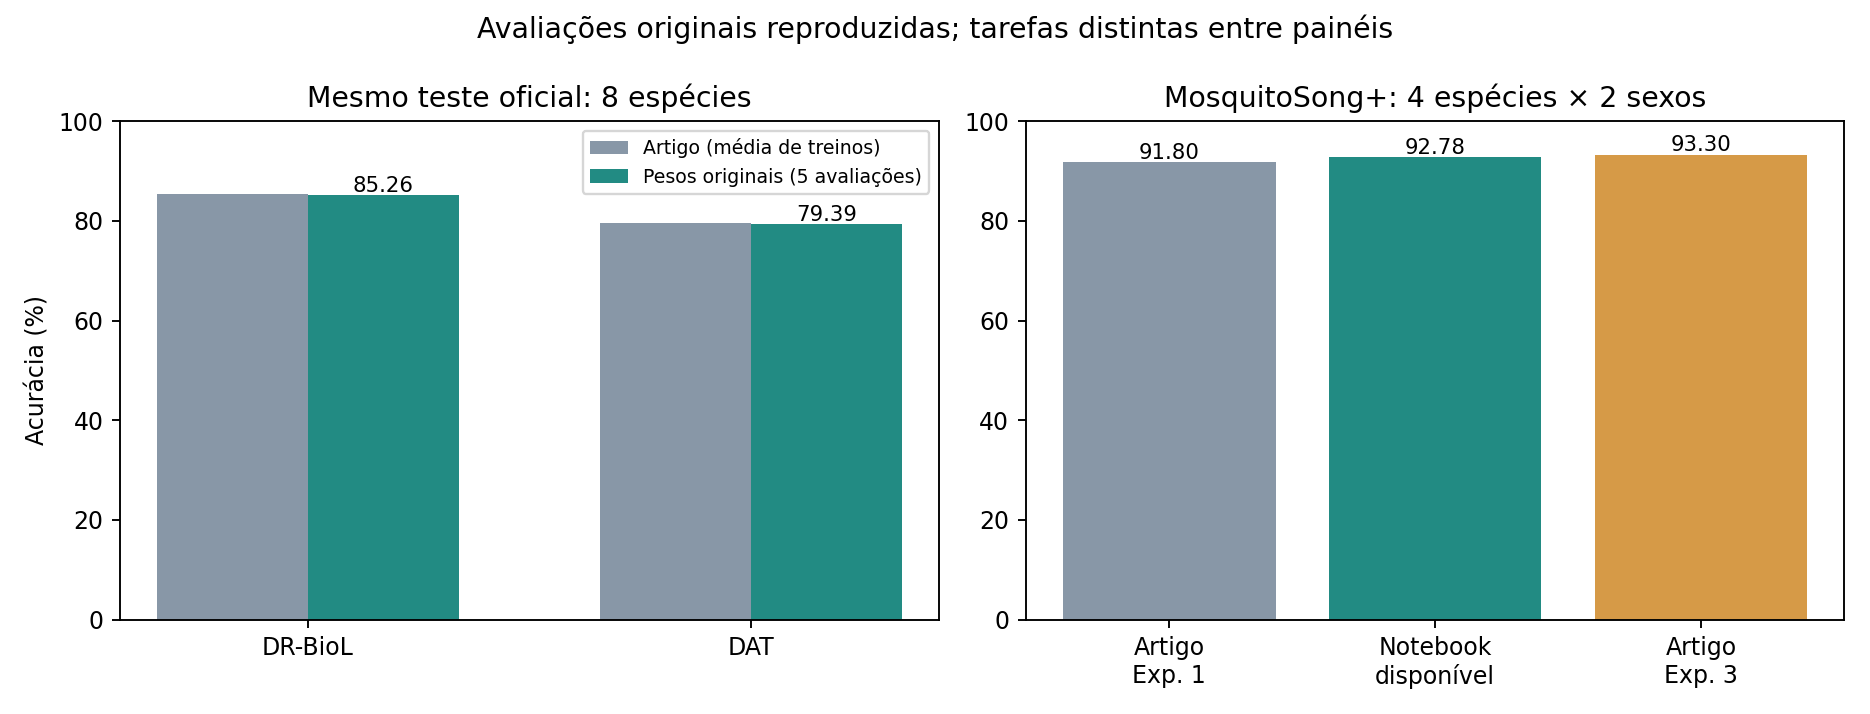

In [1]:
from pathlib import Path
import json, numpy as np, pandas as pd
from IPython.display import display, Image
out = Path('results/faithful_reproduction_2026_10_03')
display(pd.read_csv(out/'paper_comparison.csv'))
display(pd.read_csv(out/'native_binary_metrics.csv'))
display(Image(filename='reports/assets/faithful_author_accuracy.png'))


,model,precision,recall,specificity,balanced_accuracy,drive_tp,drive_n,original_author_model,task
0,prior_dryad+humbug__svm_rbf,0.653846,0.034483,0.939189,0.486836,32,107,False,"binary, unchanged frozen threshold"
1,prior_dryad__logistic,0.833333,0.324544,0.783784,0.554164,1,107,False,"binary, unchanged frozen threshold"
2,prior_humbug__svm_rbf,1.000000,0.010142,1.000000,0.505071,11,107,False,"binary, unchanged frozen threshold"
3,ridge_contrast,0.738806,0.200811,0.763514,0.482162,34,107,False,"binary, unchanged frozen threshold"
4,ridge_contrast_swarm,0.728571,0.103448,0.871622,0.487535,30,107,False,"binary, unchanged frozen threshold"
5,ridge_control,0.763158,0.058824,0.939189,0.499006,7,107,False,"binary, unchanged frozen threshold"
6,svm_multipitch,0.798561,0.450304,0.621622,0.535963,57,107,False,"binary, unchanged frozen threshold"
7,trees_multipitch,0.748663,0.283976,0.682432,0.483204,78,107,False,"binary, unchanged frozen threshold"
8,MosquitoSong+ ensemble derivado (10 pesos orig...,NaN,0.000000,1.000000,0.500000,0,107,True,binary derived from 8 labels; fixed 3 subwindo...


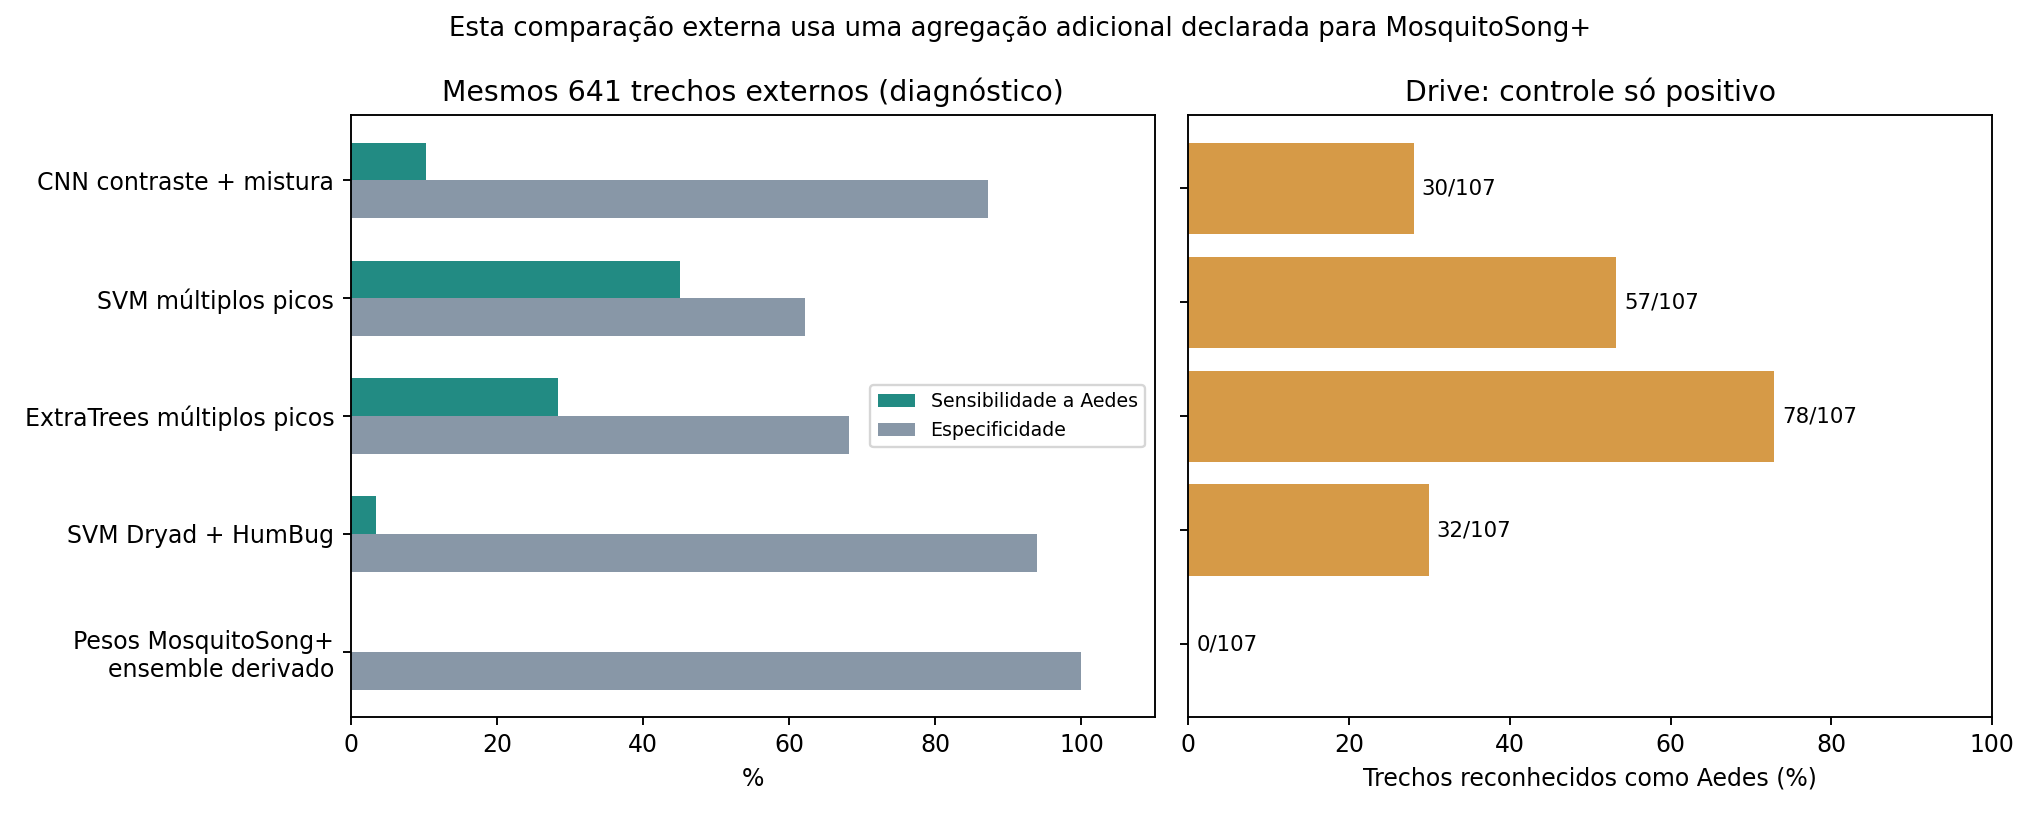

,fold,shared_train_test_recordings,overlapping_train_test_window_pairs,shared_train_val_recordings,test_epochs
0,1,12,16,2,600
1,2,12,14,29,600
2,3,13,15,28,600
3,4,11,15,28,600
4,5,10,13,28,600
5,6,10,14,28,600
6,7,11,16,27,600
7,8,10,13,24,600
8,9,9,12,28,600
9,10,11,14,42,600


In [2]:
display(pd.read_csv(out/'external_same_intervals_comparison.csv'))
display(Image(filename='reports/assets/faithful_external_comparison.png'))
display(pd.read_csv(out/'mosquitosong/split_audit.csv'))


In [3]:
from sklearn.metrics import accuracy_score, f1_score
labels, predicted = [], []
for fold in range(1,11):
    data = np.load(out/'mosquitosong'/f'fold{fold}_gain3.npz')
    labels.extend(data['y_true']); predicted.extend(data['y_pred'])
print('Recalculado dos resultados originais: n=', len(labels),
      'accuracy=', accuracy_score(labels,predicted),
      'macro_f1=', f1_score(labels,predicted,average='macro'))
for study in ['dr_biol','mosquitosong']:
    e = json.loads((out/study/'execution.json').read_text())
    print(study, e['status'], 'novo treino:', e['training_rerun'], 'commit:',e['source_commit'])
print(json.loads((out/'dr_biol/data_audit.json').read_text())['identical_feature_overlap'])


Recalculado dos resultados originais: n= 36000 accuracy= 0.9277777777777778 macro_f1= 0.9189378308082397
dr_biol complete novo treino: False commit: 1e4fea5146e40bdea3e9b3f0e36a54e6e63571e8
mosquitosong complete novo treino: False commit: 0e9187c454d7ce720cbb4925664554d1d44797c5
{'train_val': 0, 'train_test': 0, 'val_test': 0}
